# Quantum Gate Fidelity

## Objective

The objective of this notebook is to introduce quantum gates as target operations and develop quantitative measures of gate performance.

In quantum control, the goal is not simply to evolve a quantum state but rather to engineer a unitary evolution that approximates a desired quantum gate.

To evaluate control performance we introduce the notion of gate fidelity.

We will:
- Define target single-qubit gates.
- Compute the time-evolution operator from the Hamiltonian.
- Calculate gate fidelity as a function of evolution time.
- Identify the limitations of fixed-amplitude control.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

import sys
from pathlib import Path
root_path = Path.cwd().parent
sys.path.append(str(root_path / "src"))
from gates import X_gate, Y_gate, Z_gate, H_gate, I_gate, CNOT_gate, S_gate, T_gate
from hamiltonians import hamiltonian
from evolution import propagator
from fidelity import average_gate_fidelity


## Average Gate Fidelity

In this notebook, we want to evaluate how accurately the time evolution of our controlled quantum system implements a target quantum gate.

The evolution of a closed quantum system is described by a **unitary propagator**:

$$
U(t) = e^{-iHt},
$$

where $H$ is the system Hamiltonian and we use units with $\hbar=1$.

We denote the desired gate by $U_{\mathrm{target}}$ and the actual propagator by $U(t)$. Since we want to compare two quantum operations, we use the **average gate fidelity**, rather than the state fidelity defined in `fidelity.py`.

For two unitary operators acting on a $d$-dimensional Hilbert space, the average gate fidelity is

$$
F_{\mathrm{avg}}(U_{\mathrm{target}},U)
=
\frac{
\left|\operatorname{Tr}
\left(U_{\mathrm{target}}^\dagger U\right)\right|^2+d
}{
d(d+1)
}.
$$

This expression measures the agreement between the target gate and the simulated propagator, averaged over all possible pure input states.

The trace overlap quantifies how closely the two unitary operations agree, while the normalization ensures that the fidelity lies between 0 and 1. A fidelity of 1 means that the two operations are equivalent up to a global phase, which has no observable physical effect.

By computing this quantity for different evolution times, we can determine when our system most accurately approximates the desired gate.

**Assumptions:** This formula applies to unitary operations of the same dimension. It measures gate performance, not just the transfer of a particular initial state. Therefore, a high population transfer does not necessarily imply a high gate fidelity.


In [20]:
omega = 1
delta = 0.5

H_sys = hamiltonian(omega, 0.0, delta)
assert np.allclose(H_sys, H_sys.conj().T)
U_sys = propagator(H_sys, 1.0)
print("U(t):\n", U_sys)
print("Unitary:", np.allclose(
    U_sys.conj().T @ U_sys, np.eye(U_sys.shape[0])
))

U(t):
 [[ 7.60244597e-01-0.45936268j  0.00000000e+00-0.45936268j]
 [-1.25671926e-17-0.45936268j  7.60244597e-01+0.45936268j]]
Unitary: True


In [21]:
times = np.linspace(0, 2 * np.pi / np.sqrt(omega**2 + 4 * delta**2), 500)

fidelities_X = []

for t in times:
    U = propagator(H_sys, t)
    fidelities_X.append(average_gate_fidelity(X_gate, U))

fidelities_X = np.array(fidelities_X)

best_idx = np.argmax(fidelities_X)

print(f"Best X-gate fidelity: {fidelities_X[best_idx]:.6f}")
print(f"Best evolution time: {times[best_idx]:.6f}")


Best X-gate fidelity: 0.666663
Best evolution time: 2.216990


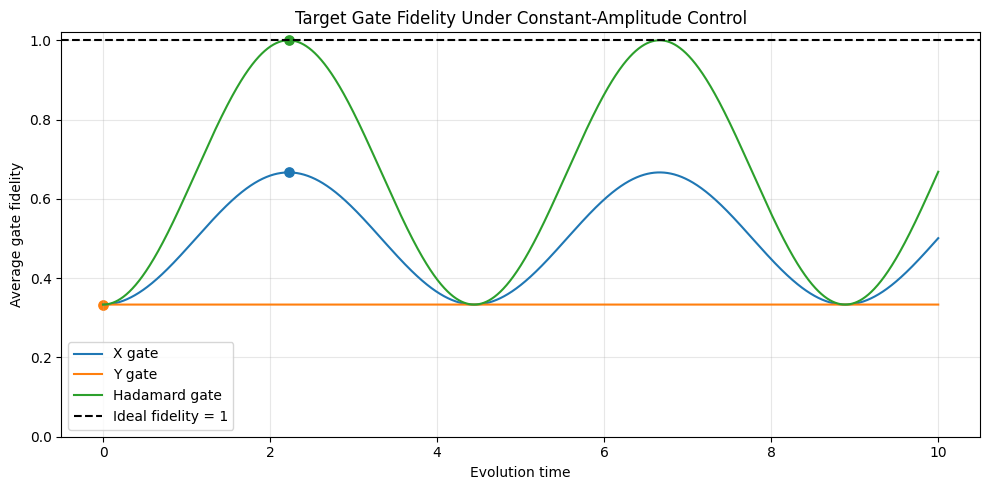

X          | Best fidelity: 0.666667 | Time: 2.2211
Y          | Best fidelity: 0.333333 | Time: 0.0000
Hadamard   | Best fidelity: 1.000000 | Time: 2.2211


In [22]:

# Target gates
target_gates = {
    "X": X_gate,
    "Y": Y_gate,
    "Hadamard": H_gate,
}

times = np.linspace(0, 10, 2000)

plt.figure(figsize=(10, 5))

results = {}

for name, U_target in target_gates.items():
    fidelities = np.array([
        average_gate_fidelity(
            U_target,
            propagator(H_sys, t)
        )
        for t in times
    ])

    best_idx = np.argmax(fidelities)
    best_fidelity = fidelities[best_idx]
    best_time = times[best_idx]

    results[name] = {
        "best_fidelity": best_fidelity,
        "best_time": best_time,
    }

    plt.plot(times, fidelities, label=f"{name} gate")
    plt.scatter(best_time, best_fidelity, s=45)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    label="Ideal fidelity = 1"
)

plt.xlabel("Evolution time")
plt.ylabel("Average gate fidelity")
plt.title("Target Gate Fidelity Under Constant-Amplitude Control")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for name, result in results.items():
    print(
        f"{name:10s} | "
        f"Best fidelity: {result['best_fidelity']:.6f} | "
        f"Time: {result['best_time']:.4f}"
    )


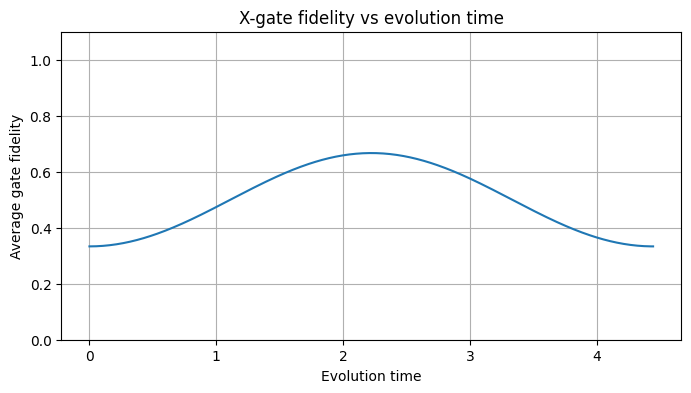

In [6]:

plt.figure(figsize=(8, 4))
plt.plot(times, fidelities_X)
plt.xlabel("Evolution time")
plt.ylabel("Average gate fidelity")
plt.title("X-gate fidelity vs evolution time")
plt.ylim(0, 1.1)
plt.grid(True)
plt.show()


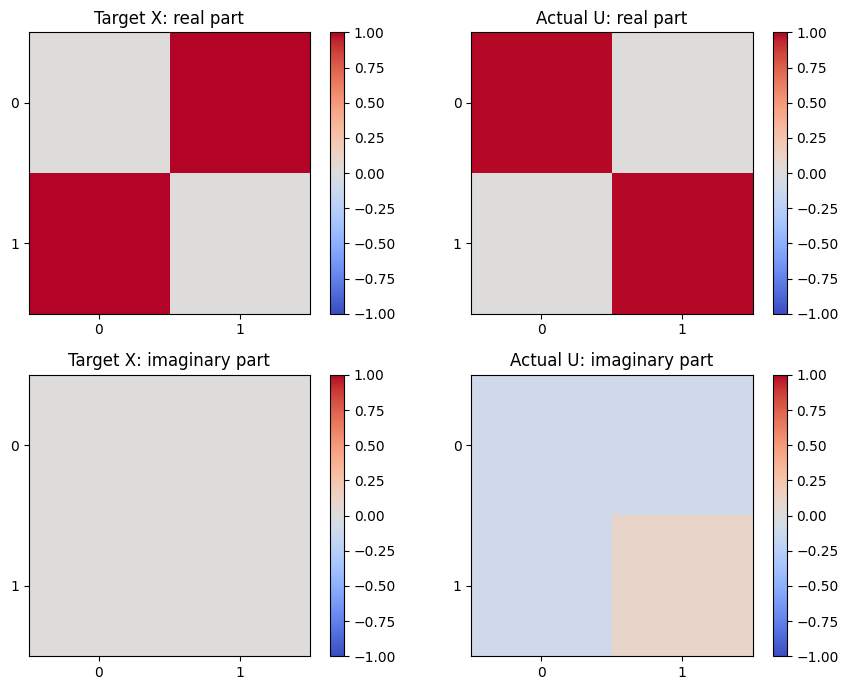

In [9]:

U_best = propagator(H_sys, best_idx)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))

matrices = [
    (axes[0, 0], X_gate.real, "Target X: real part"),
    (axes[0, 1], U_best.real, "Actual U: real part"),
    (axes[1, 0], X_gate.imag, "Target X: imaginary part"),
    (axes[1, 1], U_best.imag, "Actual U: imaginary part"),
]

for ax, matrix, title in matrices:
    im = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title(title)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


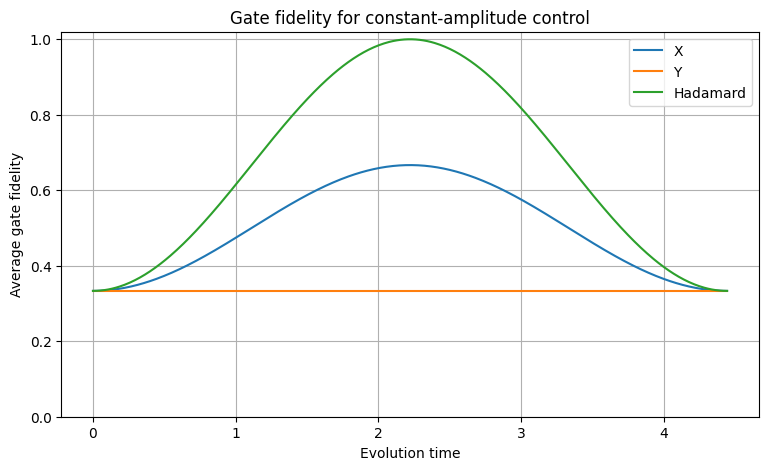

In [7]:

target_gates = {
    "X": X_gate,
    "Y": Y_gate,
    "Hadamard": H_gate
}

fidelities = {}

for name, U_target in target_gates.items():
    values = [
        average_gate_fidelity(U_target, propagator(H_sys, t))
        for t in times
    ]
    fidelities[name] = np.array(values)

plt.figure(figsize=(9, 5))

for name, values in fidelities.items():
    plt.plot(times, values, label=name)

plt.xlabel("Evolution time")
plt.ylabel("Average gate fidelity")
plt.title("Gate fidelity for constant-amplitude control")
plt.ylim(0, 1.02)
plt.grid(True)
plt.legend()
plt.show()
